# Assignment 2: Transfer Learning Across Two Datasets

**Name:** *Josh Martino*

**Prerequisite:** Transfer Learning lecture (frozen feature extraction)

This assignment uses frozen transfer learning, exactly what was covered in lecture: load a pretrained base, freeze it, add a new head, train only that. You'll do this twice, on two different datasets, and compare the results.

Data loading is provided for you below. Everything after that, building the model, training, evaluating, and reflecting, is yours to write, following the general instructions in each section.

**Submission:** GitHub repo URL and this notebook's URL on Canvas.

## Setup — Imports

In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense
from tensorflow.keras.models import Model
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

---
# Part 1: Fire/Smoke Detection

## 1A — Load the Data

In [2]:
!pip install legacy-cgi --quiet
!pip install opendatasets --quiet

import opendatasets as od
od.download("https://www.kaggle.com/datasets/phylake1337/fire-dataset")

for root, dirs, files in os.walk("fire-dataset"):
    print(root, "->", dirs[:5], f"({len(files)} files)")

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: joshmartino592
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/phylake1337/fire-dataset


100%|██████████| 387M/387M [00:07<00:00, 56.5MB/s]



fire-dataset -> ['fire_dataset'] (0 files)
fire-dataset/fire_dataset -> ['fire_images', 'non_fire_images'] (0 files)
fire-dataset/fire_dataset/fire_images -> [] (755 files)
fire-dataset/fire_dataset/non_fire_images -> [] (244 files)


In [3]:
data_dir_fire = "fire-dataset/fire_dataset"

img_size = (224, 224)
batch_size = 32

train_raw_fire = tf.keras.utils.image_dataset_from_directory(
    data_dir_fire, image_size=img_size, batch_size=batch_size,
    validation_split=0.3, subset="training", seed=42, shuffle=True
)

val_test_raw_fire = tf.keras.utils.image_dataset_from_directory(
    data_dir_fire, image_size=img_size, batch_size=batch_size,
    validation_split=0.3, subset="validation", seed=42, shuffle=True
)

val_test_batches_fire = tf.data.experimental.cardinality(val_test_raw_fire)
test_raw_fire = val_test_raw_fire.take(val_test_batches_fire // 2)
val_raw_fire = val_test_raw_fire.skip(val_test_batches_fire // 2)

class_names_fire = train_raw_fire.class_names
print("Class names:", class_names_fire)

Found 999 files belonging to 2 classes.
Using 700 files for training.
Found 999 files belonging to 2 classes.
Using 299 files for validation.
Class names: ['fire_images', 'non_fire_images']


## 1B — Inspect the Data

Before doing anything else, take a real look at what you loaded. How many images does each class have? Is there anything about the data itself that might affect how you should split it, or how you should interpret your model's results later?

Write whatever code you need to answer this for yourself.

Images per class:
fire_images        755
non_fire_images    244
Total images: 999


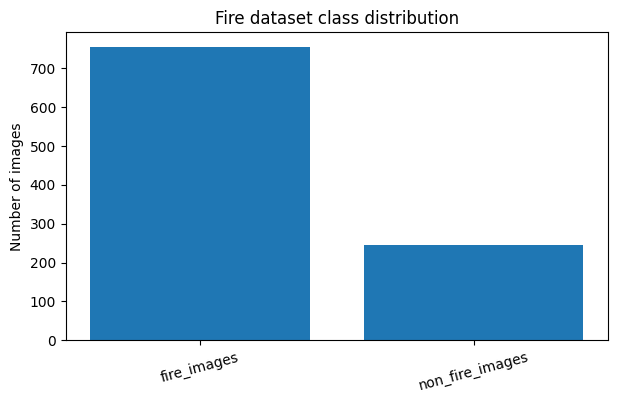

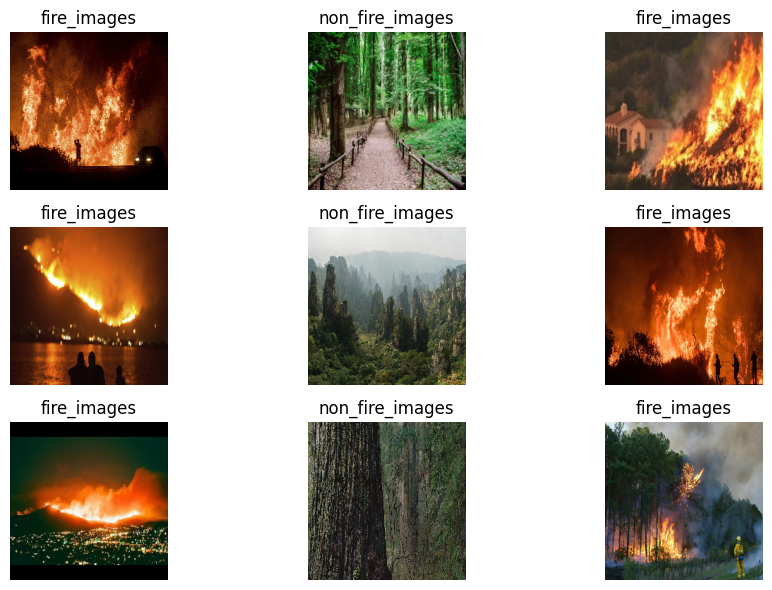

Majority-class baseline accuracy: 0.756


In [4]:
# Your exploration here

# Count the image files in each folder (including common image formats).
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp")
fire_counts = {
    name: sum(filename.lower().endswith(image_extensions)
              for filename in os.listdir(os.path.join(data_dir_fire, name)))
    for name in class_names_fire
}
print("Images per class:")
print(pd.Series(fire_counts).to_string())
print("Total images:", sum(fire_counts.values()))

plt.figure(figsize=(7, 4))
plt.bar(fire_counts.keys(), fire_counts.values())
plt.title("Fire dataset class distribution")
plt.ylabel("Number of images")
plt.xticks(rotation=15)
plt.show()

plt.figure(figsize=(10, 6))
for images, labels in train_raw_fire.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names_fire[int(labels[i])])
        plt.axis("off")
plt.tight_layout()
plt.show()

majority_fraction = max(fire_counts.values()) / sum(fire_counts.values())
print(f"Majority-class baseline accuracy: {majority_fraction:.3f}")


*What did you notice about this dataset? Does it change how you'll approach the next steps?*

The Fire dataset has more fire images than non-fire images, which creates a class imbalance. Because of this, accuracy alone might not show how well the model actually performs. I want to look at the confusion matrix to see how often the model misses real fires or incorrectly predicts fire. This is important because missing a real fire could have serious consequences.


## 1C — Build a Frozen Transfer Learning Model

Using MobileNetV2 as your pretrained base:
- Freeze the base model entirely
- Add a new output layer appropriate for this task (think about how many classes you're predicting, and what that means for your output layer's size, activation, and loss function)
- Remember the pattern from lecture for how the base model should be called

Preprocess your data (`train_raw_fire`, `val_raw_fire`, `test_raw_fire`) using MobileNetV2's expected preprocessing before building your model.

In [5]:
# Preprocess the data here
AUTOTUNE = tf.data.AUTOTUNE

# Make "fire" the positive class (1), regardless of alphabetical folder order.
fire_index = next(i for i, name in enumerate(class_names_fire)
                  if "fire" in name.lower() and "non" not in name.lower())
print("Original positive (fire) class:", class_names_fire[fire_index])

def prep_fire(images, labels):
    x = preprocess_input(tf.cast(images, tf.float32))
    y = tf.cast(tf.equal(labels, fire_index), tf.float32)
    return x, y

train_fire = train_raw_fire.map(prep_fire, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_fire = val_raw_fire.map(prep_fire, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_fire = test_raw_fire.map(prep_fire, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)


Original positive (fire) class: fire_images


In [6]:
# Build your model here
base_fire = MobileNetV2(weights="imagenet", include_top=False,
                        input_shape=(224, 224, 3))
base_fire.trainable = False

inputs_fire = tf.keras.Input(shape=(224, 224, 3))
x = base_fire(inputs_fire, training=False)  # Keep pretrained batch-normalization frozen.
x = GlobalAveragePooling2D()(x)
outputs_fire = Dense(1, activation="sigmoid")(x)
model_fire = Model(inputs_fire, outputs_fire, name="fire_frozen_mobilenetv2")
model_fire.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "fire_frozen_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [7]:
# Compile your model here
model_fire.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
print("Trainable base model:", base_fire.trainable)


Trainable base model: False


## 1D — Train and Evaluate

Epoch 1/8
22/22 ━━━━━━━━━━━━━━━━━━━━ 86s 3s/step - accuracy: 0.7943 - loss: 0.4051 - val_accuracy: 0.9353 - val_loss: 0.2596
Epoch 2/8
22/22 ━━━━━━━━━━━━━━━━━━━━ 68s 2s/step - accuracy: 0.9600 - loss: 0.1596 - val_accuracy: 0.9496 - val_loss: 0.1414
Epoch 3/8
22/22 ━━━━━━━━━━━━━━━━━━━━ 51s 2s/step - accuracy: 0.9714 - loss: 0.1068 - val_accuracy: 0.9568 - val_loss: 0.1107
Epoch 4/8
22/22 ━━━━━━━━━━━━━━━━━━━━ 52s 2s/step - accuracy: 0.9786 - loss: 0.0863 - val_accuracy: 0.9712 - val_loss: 0.0817
Epoch 5/8
22/22 ━━━━━━━━━━━━━━━━━━━━ 81s 2s/step - accuracy: 0.9814 - loss: 0.0747 - val_accuracy: 0.9640 - val_loss: 0.0778
Epoch 6/8
22/22 ━━━━━━━━━━━━━━━━━━━━ 83s 2s/step - accuracy: 0.9814 - loss: 0.0661 - val_accuracy: 0.9568 - val_loss: 0.0969
Epoch 7/8
22/22 ━━━━━━━━━━━━━━━━━━━━ 51s 2s/step - accuracy: 0.9871 - loss: 0.0599 - val_accuracy: 0.9640 - val_loss: 0.0909


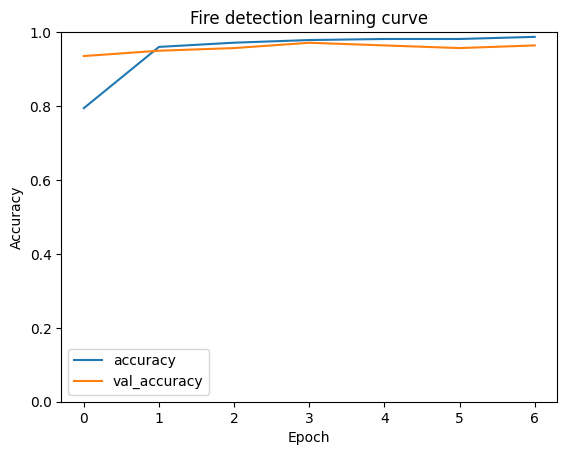

In [8]:
# Train your model here
history_fire = model_fire.fit(
    train_fire,
    validation_data=val_fire,
    epochs=8,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=2, restore_best_weights=True
    )]
)

pd.DataFrame(history_fire.history)[["accuracy", "val_accuracy"]].plot(
    title="Fire detection learning curve", xlabel="Epoch", ylabel="Accuracy"
)
plt.ylim(0, 1)
plt.show()


In [9]:
# Report validation and test accuracy here
val_loss_fire, val_acc_fire = model_fire.evaluate(val_fire, verbose=0)
test_loss_fire, test_acc_fire = model_fire.evaluate(test_fire, verbose=0)
print(f"Fire validation accuracy: {val_acc_fire:.4f} ({val_acc_fire:.1%})")
print(f"Fire test accuracy:       {test_acc_fire:.4f} ({test_acc_fire:.1%})")


Fire validation accuracy: 0.9496 (95.0%)
Fire test accuracy:       0.9688 (96.9%)


## 1E — Confusion Matrix and Discussion

Build a confusion matrix for your model's test set predictions.

**Answer:** In this context, is a false negative (missing a real fire) or a false positive (a false alarm) more costly? How might that change the decision threshold you'd actually use in practice, rather than the default 0.5?

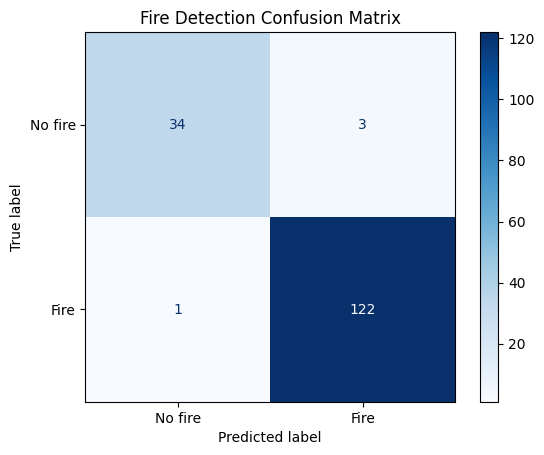

In [26]:
# Build your confusion matrix here\
y_true_fire = []
y_pred_fire = []

for images, labels in test_fire:
    predictions = model_fire(images, training=False).numpy().ravel()

    y_true_fire.extend(labels.numpy().astype(int))
    y_pred_fire.extend((predictions >= 0.5).astype(int))

cm_fire = confusion_matrix(y_true_fire, y_pred_fire)

ConfusionMatrixDisplay(
    cm_fire,
    display_labels=["No fire", "Fire"]
).plot(cmap="Blues")

plt.title("Fire Detection Confusion Matrix")
plt.show()

A false negative is more costly because it means the model missed an actual fire. My model performed well, with only 1 false negative and 3 false positives. I would consider lowering the prediction threshold to make the model more sensitive to fires, even if that increases the number of false alarms.



---
# Part 2: Satellite Land-Use Classification (EuroSAT)

## 2A — Load the Data

In [11]:
!wget -q "https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1" -O EuroSAT_RGB.zip
!unzip -q EuroSAT_RGB.zip -d eurosat_data

data_dir_sat = "eurosat_data/EuroSAT_RGB"
print(os.listdir(data_dir_sat))

['Pasture', 'SeaLake', 'HerbaceousVegetation', 'Residential', 'Industrial', 'AnnualCrop', 'River', 'Highway', 'Forest', 'PermanentCrop']


In [12]:
train_raw_sat = tf.keras.utils.image_dataset_from_directory(
    data_dir_sat, image_size=img_size, batch_size=batch_size,
    validation_split=0.3, subset="training", seed=42, shuffle=True
)

val_test_raw_sat = tf.keras.utils.image_dataset_from_directory(
    data_dir_sat, image_size=img_size, batch_size=batch_size,
    validation_split=0.3, subset="validation", seed=42, shuffle=True
)

val_test_batches_sat = tf.data.experimental.cardinality(val_test_raw_sat)
test_raw_sat = val_test_raw_sat.take(val_test_batches_sat // 2)
val_raw_sat = val_test_raw_sat.skip(val_test_batches_sat // 2)

class_names_sat = train_raw_sat.class_names
print("Class names:", class_names_sat)

Found 27000 files belonging to 10 classes.
Using 18900 files for training.
Found 27000 files belonging to 10 classes.
Using 8100 files for validation.
Class names: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


## 2B — Build a Frozen Transfer Learning Model

Same overall pattern as Part 1, but look closely at what's different about this task before you build your output layer, activation, and loss function.

Preprocess `train_raw_sat`, `val_raw_sat`, and `test_raw_sat` first.

In [19]:
# Preprocess the data here
def prep_sat(images, labels):
    return preprocess_input(tf.cast(images, tf.float32)), labels

train_sat = train_raw_sat.map(prep_sat, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_sat = val_raw_sat.map(prep_sat, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_sat = test_raw_sat.map(prep_sat, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
num_sat_classes = len(class_names_sat)
print("Number of satellite classes:", num_sat_classes)


Number of satellite classes: 10


In [20]:
# Build your model here
base_sat = MobileNetV2(weights="imagenet", include_top=False,
                       input_shape=(224, 224, 3))
base_sat.trainable = False

inputs_sat = tf.keras.Input(shape=(224, 224, 3))
x = base_sat(inputs_sat, training=False)
x = GlobalAveragePooling2D()(x)
outputs_sat = Dense(num_sat_classes, activation="softmax")(x)
model_sat = Model(inputs_sat, outputs_sat, name="eurosat_frozen_mobilenetv2")
model_sat.summary()


Model: "eurosat_frozen_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [21]:
# Compile your model here
model_sat.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",  # Integer label for one of 10 classes.
    metrics=["accuracy"]
)
print("Trainable base model:", base_sat.trainable)


Trainable base model: False


## 2C — Train and Evaluate

Epoch 1/8
591/591 ━━━━━━━━━━━━━━━━━━━━ 968s 2s/step - accuracy: 0.8810 - loss: 0.3668 - val_accuracy: 0.9304 - val_loss: 0.2176
Epoch 2/8
591/591 ━━━━━━━━━━━━━━━━━━━━ 954s 2s/step - accuracy: 0.9337 - loss: 0.1936 - val_accuracy: 0.9371 - val_loss: 0.1895
Epoch 3/8
591/591 ━━━━━━━━━━━━━━━━━━━━ 915s 2s/step - accuracy: 0.9477 - loss: 0.1580 - val_accuracy: 0.9368 - val_loss: 0.1877
Epoch 4/8
591/591 ━━━━━━━━━━━━━━━━━━━━ 919s 2s/step - accuracy: 0.9540 - loss: 0.1373 - val_accuracy: 0.9413 - val_loss: 0.1818
Epoch 5/8
591/591 ━━━━━━━━━━━━━━━━━━━━ 960s 2s/step - accuracy: 0.9610 - loss: 0.1208 - val_accuracy: 0.9398 - val_loss: 0.1778
Epoch 6/8
591/591 ━━━━━━━━━━━━━━━━━━━━ 942s 2s/step - accuracy: 0.9640 - loss: 0.1097 - val_accuracy: 0.9373 - val_loss: 0.1868
Epoch 7/8
591/591 ━━━━━━━━━━━━━━━━━━━━ 958s 2s/step - accuracy: 0.9688 - loss: 0.0984 - val_accuracy: 0.9400 - val_loss: 0.1845


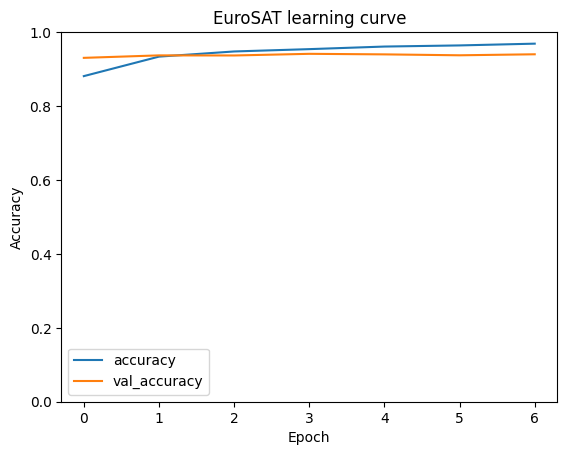

In [22]:
# Train your model here
history_sat = model_sat.fit(
    train_sat,
    validation_data=val_sat,
    epochs=8,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=2, restore_best_weights=True
    )]
)

pd.DataFrame(history_sat.history)[["accuracy", "val_accuracy"]].plot(
    title="EuroSAT learning curve", xlabel="Epoch", ylabel="Accuracy"
)
plt.ylim(0, 1)
plt.show()


In [24]:
# Report validation and test accuracy here
val_loss_sat, val_acc_sat = model_sat.evaluate(val_sat, verbose=0)
test_loss_sat, test_acc_sat = model_sat.evaluate(test_sat, verbose=0)
print(f"EuroSAT validation accuracy: {val_acc_sat:.4f} ({val_acc_sat:.1%})")
print(f"EuroSAT test accuracy:       {test_acc_sat:.4f} ({test_acc_sat:.1%})")


EuroSAT validation accuracy: 0.9398 (94.0%)
EuroSAT test accuracy:       0.9390 (93.9%)


## 2D — Confusion Matrix and Discussion

Build a confusion matrix for your model's test set predictions.

**Answer:** Which land-use classes get confused most often? Does that make visual sense to you?

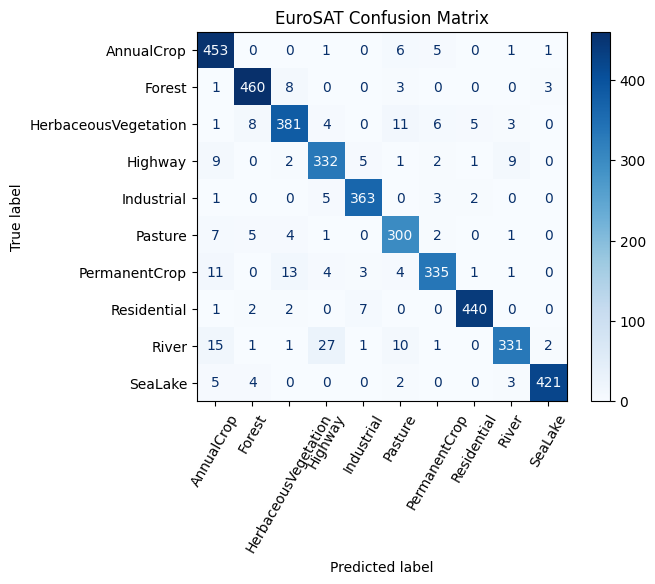

In [27]:
# Build your confusion matrix here
y_true_sat = []
y_pred_sat = []

for images, labels in test_sat:
    predictions = model_sat(images, training=False).numpy()

    y_true_sat.extend(labels.numpy().astype(int))
    y_pred_sat.extend(np.argmax(predictions, axis=1))

cm_sat = confusion_matrix(y_true_sat, y_pred_sat)

ConfusionMatrixDisplay(
    cm_sat,
    display_labels=class_names_sat
).plot(cmap="Blues", xticks_rotation=60)

plt.title("EuroSAT Confusion Matrix")
plt.show()


The EuroSAT model performed well overall, but it struggled with a few classes. The biggest confusion was River being predicted as Highway 27 times. It also predicted River as AnnualCrop 15 times and PermanentCrop as HerbaceousVegetation 13 times. These mistakes make sense because roads and rivers can have similar shapes in satellite images, while different types of vegetation can look similar from above.



---
# Part 3: Compare the Two Domains

Fill in your own results:

| | Fire/Smoke | EuroSAT |
|---|---|---|
| Validation Accuracy |95.0% | 94.0%|
| Test Accuracy |96.9% |93.9% |

**Answer:**
1. MobileNetV2 was originally trained on ImageNet, ordinary ground-level photos of everyday objects. Which of your two datasets do you think is the closer match to that original training, and which is the bigger mismatch? Use your actual results as evidence.
2. For each dataset, do you think there's room for improvement if you could adjust part of the pretrained model itself, rather than just the new layer on top? Would you expect that to matter more for one dataset than the other? Why?

1. I think the Fire dataset is closer to ImageNet because both contain regular photographs of real-world objects and environments. EuroSAT is a bigger mismatch because it uses satellite images taken from above, which have different patterns and features. My model achieved 95.0% validation accuracy on Fire and 94.0% on EuroSAT in the final epoch. Both performed well, but Fire did slightly better, which supports the idea that transfer learning works better when the original training data is similar to the new dataset.

2. I think both models could improve if I unfroze some of MobileNetV2's layers and fine-tuned them. The Fire model already performed well, so I would expect smaller improvements. EuroSAT would probably benefit more because satellite images are very different from the images MobileNetV2 was originally trained on. Fine-tuning could help the model learn features that are more specific to satellite imagery.



---
# Part 4: Reflection

Answer in 4 to 6 sentences:

1. Did anything about the Fire dataset's composition affect how you approached splitting or evaluating it? Explain.
2. What's the actual difference between the output layer, activation, and loss function you used in Part 1 versus Part 2? Why does that difference exist?
3. Based on your results, does a pretrained model's usefulness depend only on how good the model is, or also on how well its original training matches your task? Explain using your own two results as evidence.

The Fire dataset has more fire images than non-fire images, so I focused on evaluating false positives and false negatives instead of relying only on accuracy. For Fire detection, I used one output neuron with sigmoid activation and binary cross-entropy because the model is predicting between two classes. For EuroSAT, I used 10 output neurons with softmax activation and sparse categorical cross-entropy because there are 10 different land-use categories. My Fire model reached 95.0% validation accuracy, while EuroSAT reached 94.0% in the final epoch. These results suggest that a pretrained model's performance depends not only on how good the model is but also on how similar its original training data is to the new task.



---
## Done!

Save this notebook back to your GitHub fork, then submit your two links on Canvas.